# Calidad y cobertura internacional
Este notebook inspecciona los resultados calculados sobre las 41,770,880 observaciones del consolidado.

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS = PROJECT_ROOT / 'data' / '03_analysis_output' / 'calidad_cobertura'
print(RESULTS)

c:\Users\REYES\OneDrive\Desktop\terminado\portafolio data science\TSI\data\03_analysis_output\calidad_cobertura


In [3]:
global_quality = json.loads((RESULTS / 'calidad_global.json').read_text(encoding='utf-8'))
coverage = pd.read_csv(RESULTS / 'cobertura_por_fuente.csv')
ranges = pd.read_csv(RESULTS / 'controles_de_rango.csv')
print(global_quality)
display(coverage.head())
display(ranges)

{'filas_evaluadas': 41770880, 'grupos_evaluados': 5, 'controles_de_rango': {'latitud_fuera_rango': 0, 'longitud_fuera_rango': 0, 'periodo_no_positivo': 0, 'timestamp_invalido': 0, 'valor_fuente_negativo': 0, 'valor_principal_negativo': 0}, 'input': 'C:\\Users\\REYES\\OneDrive\\Desktop\\terminado\\portafolio data science\\TSI\\data\\02_clean\\consolidated\\international_observations.parquet', 'max_rows': None}


,ciudad,fuente,metrica_principal,observaciones,timestamp_minimo,timestamp_maximo,nulos_timestamp,nulos_ciudad,nulos_fuente,nulos_es_real,nulos_segmento_id,nulos_tipo_via,nulos_calidad_registro,nulos_metrica_principal,nulos_valor_principal,nulos_valor_fuente,nulos_latitud,nulos_longitud,nulos_periodo_integracion_min
0,Istanbul,istanbul_traffic_index,indice_congestion,3332,2015-08-06T00:00:00,2024-10-18T00:00:00,0,0,0,0,0,0,0,0,0,3332,3332,3332,3332
1,Los Angeles County,metr_la,velocidad_sensor,7094304,2012-03-01T00:00:00,2012-06-27T23:55:00,0,0,0,0,0,0,0,0,0,0,7094304,7094304,7094304
2,Madrid,madrid_traffic_points,intensidad,12512133,2022-12-01T00:00:00,2022-12-31T23:45:00,0,0,0,0,0,0,0,0,0,12512133,12512133,12512133,0
3,San Francisco Bay Area,pems_bay,velocidad_sensor,16937700,2017-01-01T00:00:00,2017-06-30T23:55:00,0,0,0,0,0,0,0,0,0,0,16937700,16937700,16937700
4,Sao Paulo,sao_paulo_cet,congestion_longitud_m,5223411,2001-01-02T07:30:00,2018-09-30T19:30:00,0,0,0,0,0,3323698,0,0,0,5223411,5223411,5223411,5223411


,control,registros_invalidos
0,latitud_fuera_rango,0
1,longitud_fuera_rango,0
2,periodo_no_positivo,0
3,timestamp_invalido,0
4,valor_fuente_negativo,0
5,valor_principal_negativo,0


In [4]:
summary = coverage.groupby('fuente', as_index=False).agg(
    observaciones=('observaciones', 'sum'),
    nulos_timestamp=('nulos_timestamp', 'sum'),
    nulos_valor_principal=('nulos_valor_principal', 'sum'),
    timestamp_minimo=('timestamp_minimo', 'min'),
    timestamp_maximo=('timestamp_maximo', 'max'),
)
summary['porcentaje_nulo_valor_principal'] = summary['nulos_valor_principal'] / summary['observaciones'] * 100
display(summary.sort_values('observaciones', ascending=False))

,fuente,observaciones,nulos_timestamp,nulos_valor_principal,timestamp_minimo,timestamp_maximo,porcentaje_nulo_valor_principal
3,pems_bay,16937700,0,0,2017-01-01T00:00:00,2017-06-30T23:55:00,0.0
1,madrid_traffic_points,12512133,0,0,2022-12-01T00:00:00,2022-12-31T23:45:00,0.0
2,metr_la,7094304,0,0,2012-03-01T00:00:00,2012-06-27T23:55:00,0.0
4,sao_paulo_cet,5223411,0,0,2001-01-02T07:30:00,2018-09-30T19:30:00,0.0
0,istanbul_traffic_index,3332,0,0,2015-08-06T00:00:00,2024-10-18T00:00:00,0.0


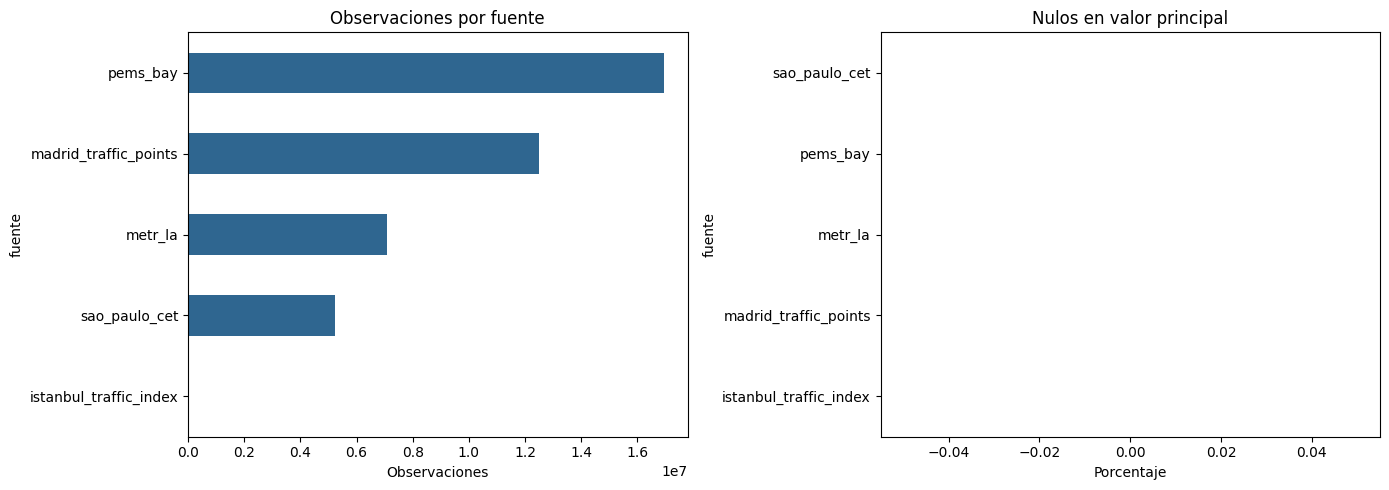

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
summary.sort_values('observaciones').plot.barh(x='fuente', y='observaciones', ax=axes[0], legend=False, color='#2f6690')
axes[0].set_title('Observaciones por fuente')
axes[0].set_xlabel('Observaciones')
summary.sort_values('porcentaje_nulo_valor_principal').plot.barh(x='fuente', y='porcentaje_nulo_valor_principal', ax=axes[1], legend=False, color='#d1495b')
axes[1].set_title('Nulos en valor principal')
axes[1].set_xlabel('Porcentaje')
plt.tight_layout()
plt.show()

## Lectura
La cobertura y los nulos se interpretan por fuente. No se mezclan unidades ni se imputa automaticamente una metrica que la fuente no mida.